# Projeto Integrador

**Arquivos utilizados:** `BALANCO_ENERGIA_SUBSISTEMA_2023.csv`, `BALANCO_ENERGIA_SUBSISTEMA_2024.csv` e `BALANCO_ENERGIA_SUBSISTEMA_2025.csv`  
**Pergunta:** Entre 2023 e 2025, quais meses apresentaram os menores e maiores valores médios de intercâmbio envolvendo os subsistemas Norte e Nordeste e como esses períodos se relacionam com o comportamento da geração por fonte?  
**Fonte:** ONS — Balanço de Energia nos Subsistemas · **Unidade:** MWmed · **Licença:** CC BY

Mantenha este notebook e os arquivos CSV na mesma pasta. Execute as células na ordem apresentada. 

## 1. Ambiente e bibliotecas


In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("Versão do Python:", sys.version.split()[0])
print("Versão do pandas:", pd.__version__)


Versão do Python: 3.14.4
Versão do pandas: 3.0.5


## 2. Caminho e carregamento dos dados


In [3]:
PASTA_DADOS = Path.cwd()
ANOS = [2023, 2024, 2025]

bases_anuais = []

for ano in ANOS:
    arquivo = PASTA_DADOS / f"BALANCO_ENERGIA_SUBSISTEMA_{ano}.csv"

    if not arquivo.exists():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {arquivo.name}. "
            "Mantenha o notebook e os arquivos CSV na mesma pasta."
        )

    base_ano = pd.read_csv(arquivo, sep=";")
    base_ano["ano_arquivo"] = ano

    print(f"{arquivo.name}: {base_ano.shape[0]} linhas e "
          f"{base_ano.shape[1]} colunas")

    bases_anuais.append(base_ano)


BALANCO_ENERGIA_SUBSISTEMA_2023.csv: 43800 linhas e 10 colunas
BALANCO_ENERGIA_SUBSISTEMA_2024.csv: 43920 linhas e 10 colunas
BALANCO_ENERGIA_SUBSISTEMA_2025.csv: 43800 linhas e 10 colunas


## 3. Validação da estrutura dos arquivos

In [4]:
colunas_referencia = set(bases_anuais[0].columns)

for ano, base_ano in zip(ANOS[1:], bases_anuais[1:]):
    colunas_ano = set(base_ano.columns)

    assert colunas_ano == colunas_referencia, (
        f"O arquivo de {ano} possui colunas diferentes "
        "das encontradas no arquivo de 2023."
    )

print("Os três arquivos apresentam a mesma estrutura de colunas.")

Os três arquivos apresentam a mesma estrutura de colunas.


## 4. Consolidação da base

In [5]:
df = pd.concat(bases_anuais, ignore_index=True)

print(
    f"Base consolidada: {df.shape[0]} linhas e "
    f"{df.shape[1]} colunas"
)

Base consolidada: 131520 linhas e 10 colunas


## 5. Primeiras inspeções


In [6]:
display(df.head())
display(df.tail())
display(df.sample(10, random_state=42))

print("Colunas da base:")
print(df.columns.tolist())

print("\nEstrutura da base:")
df.info()

print("\nTipos lidos:")
display(df.dtypes.rename("tipo_lido"))

print("\nResumo:")
display(df.describe(include="all").T)

,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio,ano_arquivo
0,NE,NORDESTE,2023-01-01 00:00:00,3874.072998,677.062988,13305.261719,1.932,10455.818,7402.512,2023
1,N,NORTE,2023-01-01 00:00:00,7858.744141,877.854980,211.772003,0.000,5990.553,2957.818,2023
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,39057.309000,5698.335000,14138.750000,21.155,58904.080,11.470,2023
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01 00:00:00,24661.111328,4071.576904,6.000000,18.223,32183.885,-3426.974,2023
4,S,SUL,2023-01-01 00:00:00,2663.381104,71.839996,615.716003,1.000,10273.827,-6921.890,2023


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio,ano_arquivo
131515,NE,NORDESTE,2025-12-31 23:00:00,3492.122,568.987,10798.684,0.0,13066.976,1792.817,2025
131516,N,NORTE,2025-12-31 23:00:00,11435.862,1860.173,299.408,0.0,7739.273,5856.170,2025
131517,SIN,SISTEMA INTERLIGADO NACIONAL,2025-12-31 23:00:00,54541.992,8267.268,11872.449,1.0,74682.710,0.000,2025
131518,SE,SUDESTE/CENTRO-OESTE,2025-12-31 23:00:00,27730.875,5679.691,187.179,0.0,42418.294,-8820.549,2025
131519,S,SUL,2025-12-31 23:00:00,11883.133,158.417,587.178,1.0,11458.166,1171.562,2025


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio,ano_arquivo
104588,SE,SUDESTE/CENTRO-OESTE,2025-05-21 13:00:00,22609.028000,5650.289000,5.000000,15411.089000,46553.762,-2878.356,2025
84663,SE,SUDESTE/CENTRO-OESTE,2024-12-06 12:00:00,28359.884766,4396.074219,7.000000,15519.092773,53682.195,-5400.143,2024
48212,SIN,SISTEMA INTERLIGADO NACIONAL,2024-02-06 18:00:00,69708.269000,8241.308000,12540.032000,596.189000,89093.940,1991.860,2024
69992,SIN,SISTEMA INTERLIGADO NACIONAL,2024-08-06 06:00:00,40521.480000,11175.312000,19439.313000,1554.485000,71585.270,1105.320,2024
44030,NE,NORDESTE,2024-01-02 22:00:00,5277.212891,823.348999,3486.618896,1.290000,14155.648,-4567.177,2024
66552,SIN,SISTEMA INTERLIGADO NACIONAL,2024-07-08 14:00:00,42797.829000,10839.323000,10118.301000,18945.646000,81104.810,1596.290,2024
32311,N,NORTE,2023-09-27 06:00:00,5930.394043,1478.791992,278.105988,133.542007,7160.728,660.106,2023
124468,SE,SUDESTE/CENTRO-OESTE,2025-11-03 05:00:00,22166.829000,7904.634000,191.063000,410.332000,36575.999,-5903.141,2025
25648,SE,SUDESTE/CENTRO-OESTE,2023-08-02 17:00:00,30309.828125,6071.108887,3.000000,638.591980,45113.759,-8091.229,2023
72098,SE,SUDESTE/CENTRO-OESTE,2024-08-23 19:00:00,31621.458984,9917.072266,11.000000,18.822001,52345.325,-10776.972,2024


Colunas da base:
['id_subsistema', 'nom_subsistema', 'din_instante', 'val_gerhidraulica', 'val_gertermica', 'val_gereolica', 'val_gersolar', 'val_carga', 'val_intercambio', 'ano_arquivo']

Estrutura da base:
<class 'pandas.DataFrame'>
RangeIndex: 131520 entries, 0 to 131519
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id_subsistema      131520 non-null  str    
 1   nom_subsistema     131520 non-null  str    
 2   din_instante       131520 non-null  str    
 3   val_gerhidraulica  131520 non-null  float64
 4   val_gertermica     131520 non-null  float64
 5   val_gereolica      131520 non-null  float64
 6   val_gersolar       131520 non-null  float64
 7   val_carga          131520 non-null  float64
 8   val_intercambio    131520 non-null  float64
 9   ano_arquivo        131520 non-null  int64  
dtypes: float64(6), int64(1), str(3)
memory usage: 14.2 MB

Tipos lidos:


id_subsistema            str
nom_subsistema           str
din_instante             str
val_gerhidraulica    float64
val_gertermica       float64
val_gereolica        float64
val_gersolar         float64
val_carga            float64
val_intercambio      float64
ano_arquivo            int64
Name: tipo_lido, dtype: object


Resumo:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_subsistema,131520,5,NE,26304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nom_subsistema,131520,5,NORDESTE,26304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
din_instante,131520,26304,2023-01-01 00:00:00,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
val_gerhidraulica,131520.0,NaN,NaN,NaN,19377.219428,18234.111224,275.270996,4396.76205,12531.1885,31118.05025,87875.71
val_gertermica,131520.0,NaN,NaN,NaN,3763.141061,3750.515962,19.0,900.66775,1842.839018,6354.021265,19869.297
val_gereolica,131520.0,NaN,NaN,NaN,4839.369841,6356.310019,0.0,112.491003,616.010488,9854.541434,25064.762
val_gersolar,131520.0,NaN,NaN,NaN,3165.834136,6092.239477,0.0,1.0,90.9285,3380.817017,42551.688
val_carga,131520.0,NaN,NaN,NaN,30968.176614,26996.656903,1364.251,10668.91925,14384.1065,48176.65575,106148.66
val_intercambio,131520.0,NaN,NaN,NaN,177.387967,5048.578535,-16172.031,-2865.05775,0.0,2851.21225,14146.508
ano_arquivo,131520.0,NaN,NaN,NaN,2024.0,0.816127,2023.0,2023.0,2024.0,2025.0,2025.0


## 6. Preparação da base


In [7]:
dados = df.rename(columns={
    "nom_subsistema": "subsistema",
    "din_instante": "data",
    "val_gerhidraulica": "hidraulica_mwmed",
    "val_gertermica": "termica_mwmed",
    "val_gereolica": "eolica_mwmed",
    "val_gersolar": "solar_mwmed",
    "val_carga": "carga_mwmed",
    "val_intercambio": "intercambio_mwmed",
}).copy()

# Conversão da variável temporal
dados["data"] = pd.to_datetime(
    dados["data"],
    errors="raise"
)

# Padronização das variáveis categóricas
dados["id_subsistema"] = dados["id_subsistema"].str.strip()
dados["subsistema"] = dados["subsistema"].str.strip()

# Criação das variáveis temporais utilizadas na análise
dados["ano"] = dados["data"].dt.year
dados["mes"] = dados["data"].dt.month
dados["mes_ano"] = dados["data"].dt.strftime("%m/%Y")

display(dados.head(10))


,id_subsistema,subsistema,data,hidraulica_mwmed,termica_mwmed,eolica_mwmed,solar_mwmed,carga_mwmed,intercambio_mwmed,ano_arquivo,ano,mes,mes_ano
0,NE,NORDESTE,2023-01-01 00:00:00,3874.072998,677.062988,13305.261719,1.932000,10455.818,7402.512,2023,2023,1,01/2023
1,N,NORTE,2023-01-01 00:00:00,7858.744141,877.854980,211.772003,0.000000,5990.553,2957.818,2023,2023,1,01/2023
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,39057.309000,5698.335000,14138.750000,21.155000,58904.080,11.470,2023,2023,1,01/2023
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01 00:00:00,24661.111328,4071.576904,6.000000,18.223000,32183.885,-3426.974,2023,2023,1,01/2023
4,S,SUL,2023-01-01 00:00:00,2663.381104,71.839996,615.716003,1.000000,10273.827,-6921.890,2023,2023,1,01/2023
5,NE,NORDESTE,2023-01-01 01:00:00,3374.273926,678.442017,12960.626953,1.013000,10481.710,6532.646,2023,2023,1,01/2023
6,N,NORTE,2023-01-01 01:00:00,8261.913086,880.137024,218.951996,0.000000,5981.216,3379.786,2023,2023,1,01/2023
7,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 01:00:00,39624.650000,5727.550000,13790.859000,20.258000,59163.320,0.000,2023,2023,1,01/2023
8,SE,SUDESTE/CENTRO-OESTE,2023-01-01 01:00:00,24306.152344,4099.463867,5.000000,18.245001,32196.682,-3767.821,2023,2023,1,01/2023
9,S,SUL,2023-01-01 01:00:00,3682.311035,69.507004,606.280029,1.000000,10503.709,-6144.611,2023,2023,1,01/2023


## 7. Validação do período dos arquivos


In [8]:
datas_fora_do_ano = dados[
    dados["ano"] != dados["ano_arquivo"]
]

assert datas_fora_do_ano.empty, (
    "Foram encontradas datas que não correspondem "
    "ao ano indicado no nome do arquivo."
)

print("As datas são compatíveis com os anos dos arquivos.")

As datas são compatíveis com os anos dos arquivos.


## 8. Diagnóstico de qualidade

In [9]:
# Valores ausentes
ausentes = dados.isna().sum().rename("qtd_ausentes")
display(ausentes)
total_ausentes = int(ausentes.sum())
print("Total de valores ausentes:", total_ausentes)

# Duplicidades
chave_registro = ["data", "id_subsistema"]
qtd_duplicatas = int(
    dados.duplicated(subset=chave_registro).sum()
)
print("Duplicidades por data e subsistema:", qtd_duplicatas)

# Categorias de subsistema
print("Categorias em id_subsistema:")
display(
    dados["id_subsistema"]
    .value_counts(dropna=False)
    .rename("qtd_registros")
)
print("Categorias em subsistema:")
display(
    dados["subsistema"]
    .value_counts(dropna=False)
    .rename("qtd_registros")
)
correspondencia_subsistemas = (
    dados[["id_subsistema", "subsistema"]]
    .drop_duplicates()
    .sort_values("id_subsistema")
)
print("Correspondência entre código e nome:")
display(correspondencia_subsistemas)
nomes_por_codigo = (
    dados.groupby("id_subsistema")["subsistema"].nunique()
)
codigos_por_nome = (
    dados.groupby("subsistema")["id_subsistema"].nunique()
)
assert nomes_por_codigo.eq(1).all(), (
    "Há códigos associados a mais de um nome de subsistema."
)
assert codigos_por_nome.eq(1).all(), (
    "Há nomes associados a mais de um código de subsistema."
)

# Tipos e formatos
colunas_numericas = [
    "hidraulica_mwmed",
    "termica_mwmed",
    "eolica_mwmed",
    "solar_mwmed",
    "carga_mwmed",
    "intercambio_mwmed",
]
tipos_invalidos = [
    coluna for coluna in colunas_numericas
    if not pd.api.types.is_numeric_dtype(dados[coluna])
]
assert not tipos_invalidos, (
    "As seguintes variáveis deveriam ser numéricas: "
    f"{tipos_invalidos}"
)
assert pd.api.types.is_datetime64_any_dtype(dados["data"]), (
    "A coluna 'data' não está no formato datetime."
)

# Abrangência temporal
data_inicial = dados["data"].min()
data_final = dados["data"].max()
print(
    "Período da base:",
    data_inicial.strftime("%d/%m/%Y %H:%M"),
    "a",
    data_final.strftime("%d/%m/%Y %H:%M")
)

# Frequência horária
intervalos = (
    dados.sort_values(["id_subsistema", "data"])
    .groupby("id_subsistema")["data"]
    .diff()
)
qtd_intervalos_invalidos = int(
    intervalos.dropna()
    .ne(pd.Timedelta(hours=1))
    .sum()
)
print(
    "Intervalos diferentes de uma hora:",
    qtd_intervalos_invalidos
)

# Quantidade de subsistemas por instante
subsistemas_por_instante = (
    dados.groupby("data")["id_subsistema"].nunique()
)
qtd_subsistemas = dados["id_subsistema"].nunique()
instantes_incompletos = int(
    subsistemas_por_instante.ne(qtd_subsistemas).sum()
)
print(
    "Instantes sem todos os subsistemas:",
    instantes_incompletos
)

id_subsistema        0
subsistema           0
data                 0
hidraulica_mwmed     0
termica_mwmed        0
eolica_mwmed         0
solar_mwmed          0
carga_mwmed          0
intercambio_mwmed    0
ano_arquivo          0
ano                  0
mes                  0
mes_ano              0
Name: qtd_ausentes, dtype: int64

Total de valores ausentes: 0
Duplicidades por data e subsistema: 0
Categorias em id_subsistema:


id_subsistema
NE     26304
N      26304
SIN    26304
SE     26304
S      26304
Name: qtd_registros, dtype: int64

Categorias em subsistema:


subsistema
NORDESTE                        26304
NORTE                           26304
SISTEMA INTERLIGADO NACIONAL    26304
SUDESTE/CENTRO-OESTE            26304
SUL                             26304
Name: qtd_registros, dtype: int64

Correspondência entre código e nome:


,id_subsistema,subsistema
1,N,NORTE
0,NE,NORDESTE
4,S,SUL
3,SE,SUDESTE/CENTRO-OESTE
2,SIN,SISTEMA INTERLIGADO NACIONAL


Período da base: 01/01/2023 00:00 a 31/12/2025 23:00
Intervalos diferentes de uma hora: 0
Instantes sem todos os subsistemas: 0


## 9. Verificação do sinal de intercâmbio líquido

In [10]:
# Soma das fontes de geração
dados["geracao_total_mwmed"] = (
    dados["hidraulica_mwmed"]
    + dados["termica_mwmed"]
    + dados["eolica_mwmed"]
    + dados["solar_mwmed"]
)

# Saldo entre geração e carga
dados["saldo_geracao_carga_mwmed"] = (
    dados["geracao_total_mwmed"]
    - dados["carga_mwmed"]
)

# Classifica o subsistema como exportador, importador ou equilibrado
dados["condicao_balanco"] = np.select(
    [
        dados["saldo_geracao_carga_mwmed"] > 0,
        dados["saldo_geracao_carga_mwmed"] < 0
    ],
    [
        "Exportador",
        "Importador"
    ],
    default="Equilíbrio"
)

# Classifica o sinal do intercâmbio
dados["sinal_intercambio"] = np.select(
    [
        dados["intercambio_mwmed"] > 0,
        dados["intercambio_mwmed"] < 0
    ],
    [
        "Positivo",
        "Negativo"
    ],
    default="Zero"
)

# Seleciona somente Norte e Nordeste
dados_N_NE = dados[
    dados["id_subsistema"].isin(["N", "NE"])
].copy()

# Compara condição energética e sinal do intercâmbio
tabela_sinal = pd.crosstab(
    [dados_N_NE["id_subsistema"], dados_N_NE["condicao_balanco"]],
    dados_N_NE["sinal_intercambio"]
)

display(tabela_sinal)

sinal_intercambio               Negativo  Positivo
id_subsistema condicao_balanco                    
N             Exportador               0     13967
              Importador           12337         0
NE            Exportador               0     23345
              Importador            2959         0

A comparação entre o saldo geração-carga e o intercâmbio líquido mostrou que, para os subsistemas Norte e Nordeste, todos os registros em condição exportadora apresentaram intercâmbio positivo, enquanto todos os registros em condição importadora apresentaram intercâmbio negativo. Dessa forma, nesta análise, valores positivos representam exportação líquida e valores negativos representam importação líquida.

## 10. Verificação de valores negativos e extremos

In [11]:
# Variáveis que não devem apresentar valores negativos
variaveis_nao_negativas = [
    "hidraulica_mwmed",
    "termica_mwmed",
    "eolica_mwmed",
    "solar_mwmed",
    "carga_mwmed",
]

# Verificação de valores negativos
negativos = (
    dados[variaveis_nao_negativas]
    .lt(0)
    .sum()
    .rename("qtd_valores_negativos")
)
display(negativos)
assert negativos.sum() == 0, (
    "Foram encontrados valores negativos em variáveis que deveriam ser não negativas."
)

# Verificação de valores extremos
resumo_extremos = []
for subsistema, grupo in dados.groupby("id_subsistema"):
    for coluna in colunas_numericas:
        q1 = grupo[coluna].quantile(0.25)
        q3 = grupo[coluna].quantile(0.75)
        iqr = q3 - q1
        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr
        qtd_extremos = (
            (grupo[coluna] < limite_inferior) |
            (grupo[coluna] > limite_superior)
        ).sum()
        resumo_extremos.append({
            "subsistema": subsistema,
            "variavel": coluna,
            "limite_inferior_iqr": limite_inferior,
            "limite_superior_iqr": limite_superior,
            "qtd_valores_extremos": qtd_extremos
        })
resumo_extremos = pd.DataFrame(resumo_extremos)
display(resumo_extremos)

hidraulica_mwmed    0
termica_mwmed       0
eolica_mwmed        0
solar_mwmed         0
carga_mwmed         0
Name: qtd_valores_negativos, dtype: int64

,subsistema,variavel,limite_inferior_iqr,limite_superior_iqr,qtd_valores_extremos
0,N,hidraulica_mwmed,-9891.028839,24868.622772,0
1,N,termica_mwmed,-1026.951996,4586.390045,0
2,N,eolica_mwmed,-302.726872,728.248120,0
3,N,solar_mwmed,-1137.941973,1896.569954,694
4,N,carga_mwmed,5577.526875,9949.077875,182
5,N,intercambio_mwmed,-13279.116250,17729.009750,0
6,NE,hidraulica_mwmed,-1021.637916,8155.576695,11
7,NE,termica_mwmed,-56.723530,1021.450524,4277
8,NE,eolica_mwmed,-3178.870783,25358.491670,0
9,NE,solar_mwmed,-8179.225619,13634.753365,1


## 11. Validações finais

In [12]:
assert total_ausentes == 0, (
    f"Foram encontrados {total_ausentes} valores ausentes."
)
assert qtd_duplicatas == 0, (
    f"Foram encontradas {qtd_duplicatas} duplicidades."
)
assert qtd_intervalos_invalidos == 0, (
    "A série possui intervalos diferentes de uma hora."
)
assert instantes_incompletos == 0, (
    "Há instantes sem registros para todos os subsistemas."
)
print("As validações foram concluídas.")

As validações foram concluídas.


## 12. Seleção dos subsistemas Norte e Nordeste

In [13]:
dados_N_NE = dados[
    dados["id_subsistema"].isin(["N", "NE"])
].copy()
print("Quantidade de registros:", len(dados_N_NE))
display(dados_N_NE.head())

Quantidade de registros: 52608


,id_subsistema,subsistema,data,hidraulica_mwmed,termica_mwmed,eolica_mwmed,solar_mwmed,carga_mwmed,intercambio_mwmed,ano_arquivo,ano,mes,mes_ano,geracao_total_mwmed,saldo_geracao_carga_mwmed,condicao_balanco,sinal_intercambio
0,NE,NORDESTE,2023-01-01 00:00:00,3874.072998,677.062988,13305.261719,1.932,10455.818,7402.512,2023,2023,1,01/2023,17858.329705,7402.511705,Exportador,Positivo
1,N,NORTE,2023-01-01 00:00:00,7858.744141,877.854980,211.772003,0.000,5990.553,2957.818,2023,2023,1,01/2023,8948.371124,2957.818124,Exportador,Positivo
5,NE,NORDESTE,2023-01-01 01:00:00,3374.273926,678.442017,12960.626953,1.013,10481.710,6532.646,2023,2023,1,01/2023,17014.355896,6532.645896,Exportador,Positivo
6,N,NORTE,2023-01-01 01:00:00,8261.913086,880.137024,218.951996,0.000,5981.216,3379.786,2023,2023,1,01/2023,9361.002106,3379.786106,Exportador,Positivo
10,NE,NORDESTE,2023-01-01 02:00:00,2631.370117,678.745972,12754.953125,0.933,10475.740,5590.262,2023,2023,1,01/2023,16066.002214,5590.262214,Exportador,Positivo


## 13. Construção da tabela analítica

In [14]:

tabela_mensal = (
    dados_N_NE
    .groupby(
        ["id_subsistema", "subsistema", "ano", "mes", "mes_ano"]
    )
    .agg(
        intercambio_medio=(
            "intercambio_mwmed", "mean"
        ),
        intercambio_mediano=(
            "intercambio_mwmed", "median"
        ),
        intercambio_p25=(
            "intercambio_mwmed",
            lambda x: x.quantile(0.25)
        ),
        intercambio_p75=(
            "intercambio_mwmed",
            lambda x: x.quantile(0.75)
        ),
        hidraulica_media=(
            "hidraulica_mwmed", "mean"
        ),
        termica_media=(
            "termica_mwmed", "mean"
        ),
        eolica_media=(
            "eolica_mwmed", "mean"
        ),
        solar_media=(
            "solar_mwmed", "mean"
        ),
        carga_media=(
            "carga_mwmed", "mean"
        )
    )
    .reset_index()
)
# Ordena a tabela por subsistema, ano e mês
tabela_mensal = tabela_mensal.sort_values(
    ["id_subsistema", "ano", "mes"]
)

# Exibe a tabela final
display(tabela_mensal.head(24))

print("Dimensão da tabela mensal:", tabela_mensal.shape)
assert tabela_mensal.shape[0] == 72
print("Tabela mensal construída com sucesso.")

,id_subsistema,subsistema,ano,mes,mes_ano,intercambio_medio,intercambio_mediano,intercambio_p25,intercambio_p75,hidraulica_media,termica_media,eolica_media,solar_media,carga_media
0,N,NORTE,2023,1,01/2023,7592.816879,7990.0205,6001.13400,9830.94100,12260.671866,1451.421179,181.202250,1.116935,6301.595374
1,N,NORTE,2023,2,02/2023,7952.226987,8252.3540,6701.01625,9751.97650,13343.701029,879.435459,160.340286,1.229963,6432.479734
2,N,NORTE,2023,3,03/2023,8157.703374,8299.6750,6581.42800,9631.10125,13830.909730,879.679499,97.576590,0.994613,6651.457082
3,N,NORTE,2023,4,04/2023,8761.999069,9099.5135,6888.79700,10649.41250,14084.655547,1394.994715,67.523367,13.074940,6798.249494
4,N,NORTE,2023,5,05/2023,5965.778488,5868.6335,4350.64250,7611.46800,11872.386698,917.074342,125.493020,240.989714,7190.165301
5,N,NORTE,2023,6,06/2023,3238.118072,2830.1995,1625.76925,4802.98500,7916.569683,2037.918890,120.613822,278.862941,7115.847258
6,N,NORTE,2023,7,07/2023,-147.844578,-690.3130,-1661.07600,889.33125,4976.703943,1565.425671,206.258797,314.240148,7210.473133
7,N,NORTE,2023,8,08/2023,-1586.327030,-1792.8290,-2347.79375,-1192.37450,3907.435529,1452.550977,274.848108,335.860914,7557.022560
8,N,NORTE,2023,9,09/2023,-2047.041054,-2313.7895,-2897.63050,-1453.38900,3616.504170,1379.068078,339.263493,365.098244,7746.975040
9,N,NORTE,2023,10,10/2023,-1618.020034,-1946.9465,-2506.42600,-795.00475,3969.488973,1462.138446,348.014690,366.243258,7763.905405


Dimensão da tabela mensal: (72, 14)
Tabela mensal construída com sucesso.


## 14. Identificação dos meses com menores e maiores valores médios de intercâmbio

In [15]:
# Cinco menores valores médios por ano e subsistema
menores = (
    tabela_mensal
    .sort_values(
        ["id_subsistema", "ano", "intercambio_medio"]
    )
    .groupby(["id_subsistema", "ano"])
    .head(5)
    .copy()
)

# Cinco maiores valores médios por ano e subsistema
maiores = (
    tabela_mensal
    .sort_values(
        ["id_subsistema", "ano", "intercambio_medio"],
        ascending=[True, True, False]
    )
    .groupby(["id_subsistema", "ano"])
    .head(5)
    .copy()
)

# Apresentação dos resultados
colunas_intercambio = [
    "id_subsistema",
    "ano",
    "mes",
    "mes_ano",
    "intercambio_medio",
    "intercambio_mediano",
    "intercambio_p25",
    "intercambio_p75"
]
print("Cinco meses com MENORES valores médios de intercâmbio, por ano:")
display(
    menores[colunas_intercambio]
    .sort_values(
        ["id_subsistema", "ano", "intercambio_medio"]
    )
    .round(2)
)
print("Cinco meses com MAIORES valores médios de intercâmbio, por ano:")
display(
    maiores[colunas_intercambio]
    .sort_values(
        ["id_subsistema", "ano", "intercambio_medio"],
        ascending=[True, True, False]
    )
    .round(2)
)

# Verificação da recorrência dos meses
# Conta em quantos dos três anos cada mês apareceu entre os cinco menores valores
frequencia_menores = (
    menores
    .groupby(["id_subsistema", "mes"])
    .size()
    .reset_index(name="qtd_anos")
)
# Conta em quantos dos três anos cada mês apareceu entre os cinco maiores valores
frequencia_maiores = (
    maiores
    .groupby(["id_subsistema", "mes"])
    .size()
    .reset_index(name="qtd_anos")
)

# Meses que apareceram nos três anos
recorrentes_menores = frequencia_menores[
    frequencia_menores["qtd_anos"] == 3
].copy()
recorrentes_maiores = frequencia_maiores[
    frequencia_maiores["qtd_anos"] == 3
].copy()

# Adiciona o nome do mês para facilitar a leitura
nomes_meses = {
    1: "Jan",
    2: "Fev",
    3: "Mar",
    4: "Abr",
    5: "Mai",
    6: "Jun",
    7: "Jul",
    8: "Ago",
    9: "Set",
    10: "Out",
    11: "Nov",
    12: "Dez"
}
recorrentes_menores["nome_mes"] = (
    recorrentes_menores["mes"].map(nomes_meses)
)
recorrentes_maiores["nome_mes"] = (
    recorrentes_maiores["mes"].map(nomes_meses)
)
print(
    "Meses que estiveram entre os cinco MENORES valores médios nos três anos:"
)
display(
    recorrentes_menores[
        ["id_subsistema", "mes", "nome_mes", "qtd_anos"]
    ]
)
print(
    "Meses que estiveram entre os cinco MAIORES valores médios nos três anos:"
)
display(
    recorrentes_maiores[
        ["id_subsistema", "mes", "nome_mes", "qtd_anos"]
    ]
)

Cinco meses com MENORES valores médios de intercâmbio, por ano:


,id_subsistema,ano,mes,mes_ano,intercambio_medio,intercambio_mediano,intercambio_p25,intercambio_p75
11,N,2023,12,12/2023,-2129.67,-2157.73,-2731.95,-1577.47
8,N,2023,9,09/2023,-2047.04,-2313.79,-2897.63,-1453.39
10,N,2023,11,11/2023,-1699.92,-1794.69,-2434.65,-1111.03
9,N,2023,10,10/2023,-1618.02,-1946.95,-2506.43,-795.00
7,N,2023,8,08/2023,-1586.33,-1792.83,-2347.79,-1192.37
20,N,2024,9,09/2024,-1969.28,-2040.27,-2687.94,-1417.69
19,N,2024,8,08/2024,-1715.62,-1780.24,-2407.92,-1145.03
22,N,2024,11,11/2024,-1348.12,-1447.86,-2183.52,-791.73
21,N,2024,10,10/2024,-1292.11,-1370.66,-2221.04,-537.93
18,N,2024,7,07/2024,-1091.78,-1301.27,-1974.67,-773.36


Cinco meses com MAIORES valores médios de intercâmbio, por ano:


,id_subsistema,ano,mes,mes_ano,intercambio_medio,intercambio_mediano,intercambio_p25,intercambio_p75
3,N,2023,4,04/2023,8762.00,9099.51,6888.80,10649.41
2,N,2023,3,03/2023,8157.70,8299.67,6581.43,9631.10
1,N,2023,2,02/2023,7952.23,8252.35,6701.02,9751.98
0,N,2023,1,01/2023,7592.82,7990.02,6001.13,9830.94
4,N,2023,5,05/2023,5965.78,5868.63,4350.64,7611.47
14,N,2024,3,03/2024,7455.75,7260.41,5715.28,9417.50
15,N,2024,4,04/2024,7093.07,7331.83,4637.63,9620.52
16,N,2024,5,05/2024,6149.88,6589.62,3201.80,8747.14
13,N,2024,2,02/2024,6035.99,6098.76,4094.78,7996.56
23,N,2024,12,12/2024,532.97,-234.48,-1005.42,1582.11


Meses que estiveram entre os cinco MENORES valores médios nos três anos:


,id_subsistema,mes,nome_mes,qtd_anos
1,N,8,Ago,3
2,N,9,Set,3
3,N,10,Out,3
4,N,11,Nov,3
6,NE,1,Jan,3
7,NE,2,Fev,3
8,NE,3,Mar,3
9,NE,4,Abr,3


Meses que estiveram entre os cinco MAIORES valores médios nos três anos:


,id_subsistema,mes,nome_mes,qtd_anos
1,N,2,Fev,3
2,N,3,Mar,3
3,N,4,Abr,3
4,N,5,Mai,3
6,NE,6,Jun,3
7,NE,7,Jul,3
8,NE,8,Ago,3
9,NE,9,Set,3
10,NE,10,Out,3


## 15. Comparação mensal entre 2023, 2024 e 2025

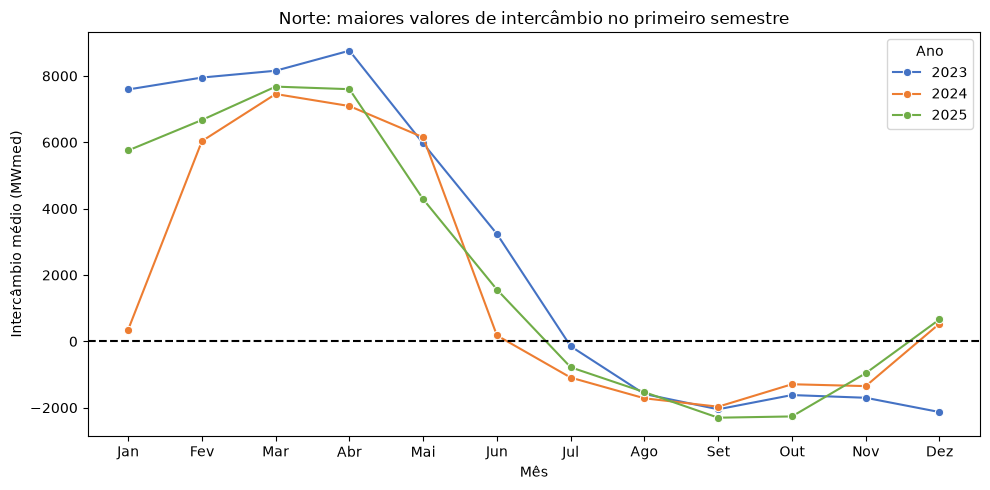

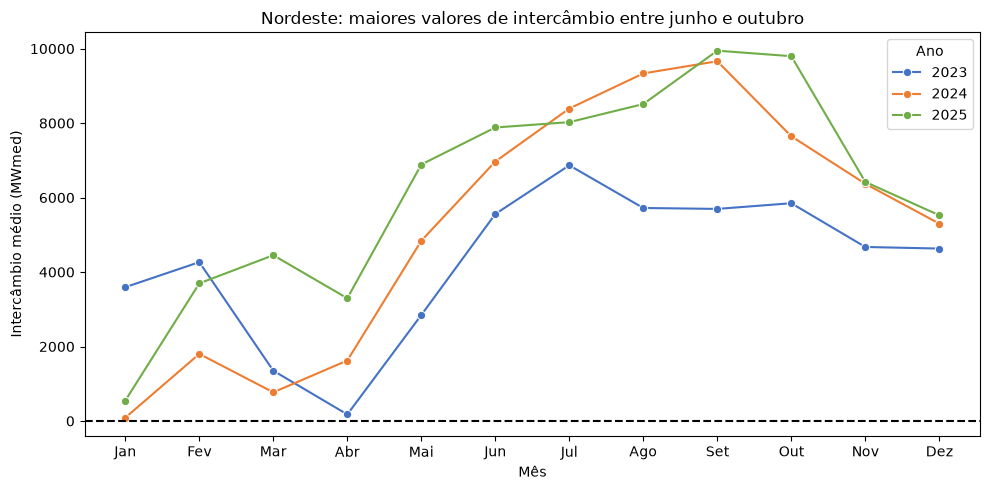

In [16]:
nomes_meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

# Cores utilizadas para cada ano
cores_anos = {
    2023: "#4472C4",  # azul
    2024: "#ED7D31",  # laranja
    2025: "#70AD47"   # verde
}

titulos_intercambio = {
    "N": "Norte: maiores valores de intercâmbio no primeiro semestre",
    "NE": "Nordeste: maiores valores de intercâmbio entre junho e outubro"
}

for subsistema in ["N", "NE"]:

    grafico = tabela_mensal[
        tabela_mensal["id_subsistema"] == subsistema
    ]

    plt.figure(figsize=(10, 5))

    sns.lineplot(
        data=grafico,
        x="mes",
        y="intercambio_medio",
        hue="ano",
        marker="o",
        palette=cores_anos
    )

    plt.axhline(
        y=0,
        color="black",
        linestyle="--"
    )

    plt.title(titulos_intercambio[subsistema])

    plt.xlabel("Mês")
    plt.ylabel("Intercâmbio médio (MWmed)")

    plt.xticks(
        range(1, 13),
        nomes_meses
    )

    plt.legend(title="Ano")
    plt.tight_layout()
    plt.show()

## 16. Distribuição mensal do intercâmbio

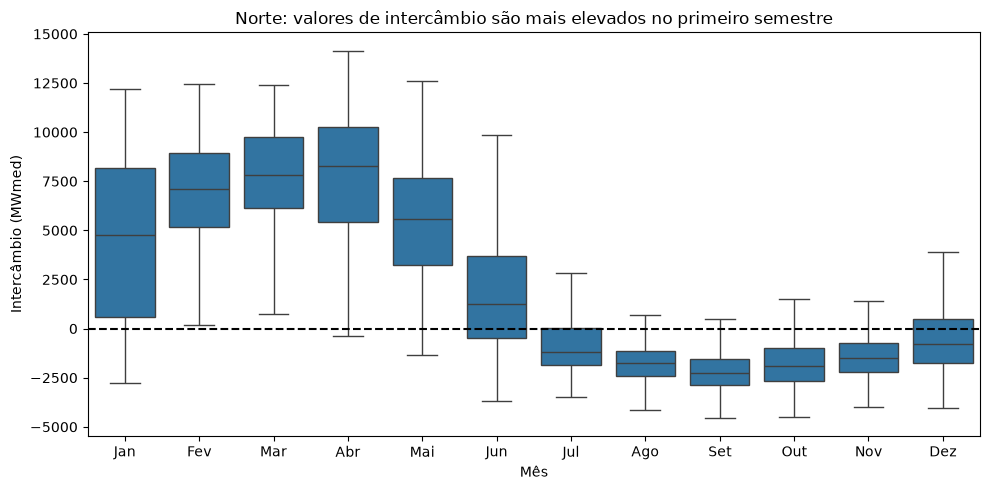

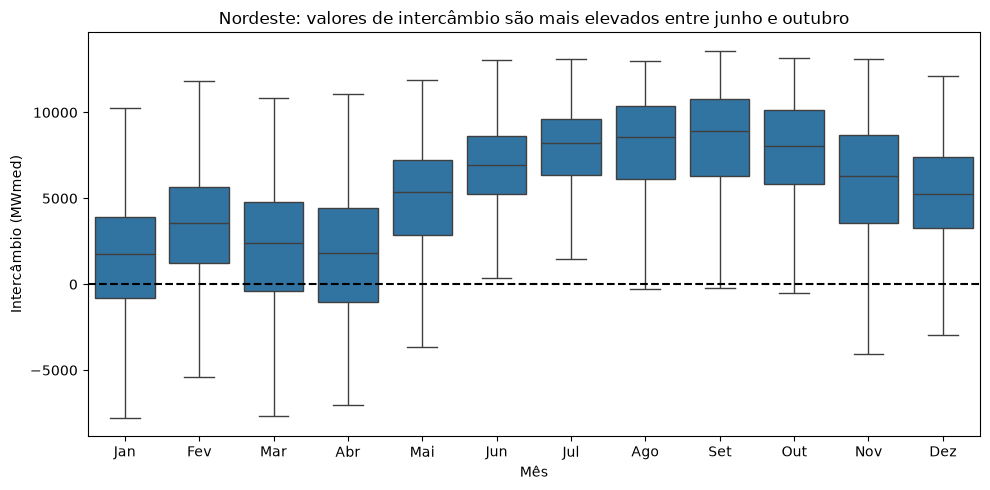

In [17]:
# Criação do nome do mês na base horária
mapa_meses = {
    1: "Jan",
    2: "Fev",
    3: "Mar",
    4: "Abr",
    5: "Mai",
    6: "Jun",
    7: "Jul",
    8: "Ago",
    9: "Set",
    10: "Out",
    11: "Nov",
    12: "Dez"
}

dados_N_NE["nome_mes"] = (
    dados_N_NE["mes"].map(mapa_meses)
)

titulos_distribuicao = {
    "N": "Norte: valores de intercâmbio são mais elevados no primeiro semestre",
    "NE": "Nordeste: valores de intercâmbio são mais elevados entre junho e outubro"
}

for subsistema in ["N", "NE"]:

    grafico = dados_N_NE[
        dados_N_NE["id_subsistema"] == subsistema
    ]

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=grafico,
        x="nome_mes",
        y="intercambio_mwmed",
        order=nomes_meses,
        showfliers=False
    )

    plt.axhline(
        y=0,
        color="black",
        linestyle="--"
    )

    plt.title(
        titulos_distribuicao[subsistema]
    )

    plt.xlabel("Mês")
    plt.ylabel("Intercâmbio (MWmed)")

    plt.tight_layout()
    plt.show()

## 17. Relação entre o intercâmbio e a geração por fonte

In [18]:
titulos_geracao = {
    "N": "Norte: intercâmbio acompanha a sazonalidade da geração hidráulica",
    "NE": "Nordeste: maiores intercâmbios coincidem com maior geração eólica"
}

for subsistema in ["N", "NE"]:

    grafico = tabela_mensal[
        tabela_mensal["id_subsistema"] == subsistema
    ].copy()

    grafico["data_mes"] = pd.to_datetime(
        grafico["ano"].astype(str)
        + "-"
        + grafico["mes"].astype(str)
        + "-01"
    )

    grafico_interativo = grafico.melt(
        id_vars=["data_mes"],
        value_vars=[
            "intercambio_medio",
            "hidraulica_media",
            "termica_media",
            "eolica_media",
            "solar_media"
        ],
        var_name="variavel",
        value_name="valor_mwmed"
    )

    grafico_interativo["variavel"] = (
        grafico_interativo["variavel"].replace({
            "intercambio_medio": "Intercâmbio",
            "hidraulica_media": "Hidráulica",
            "termica_media": "Térmica",
            "eolica_media": "Eólica",
            "solar_media": "Solar"
        })
    )

    fig = px.line(
        grafico_interativo,
        x="data_mes",
        y="valor_mwmed",
        color="variavel",
        markers=True,
        title=titulos_geracao[subsistema],
        labels={
            "data_mes": "Período",
            "valor_mwmed": "MWmed",
            "variavel": "Variável"
        }
    )

    fig.add_hline(
        y=0,
        line_dash="dash",
        line_color="black"
    )

    fig.show()